DATASET IRIS


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Jumlah data latih: 120
Jumlah data uji: 30

Model berhasil dilatih.

HASIL PREDIKSI


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Kelas Aktual,Hasil Prediksi
38,4.4,3.0,1.3,0.2,setosa,setosa
127,6.1,3.0,4.9,1.8,virginica,virginica
57,4.9,2.4,3.3,1.0,versicolor,versicolor
93,5.0,2.3,3.3,1.0,versicolor,versicolor
42,4.4,3.2,1.3,0.2,setosa,setosa
56,6.3,3.3,4.7,1.6,versicolor,versicolor
22,4.6,3.6,1.0,0.2,setosa,setosa
20,5.4,3.4,1.7,0.2,setosa,setosa
147,6.5,3.0,5.2,2.0,virginica,virginica
84,5.4,3.0,4.5,1.5,versicolor,versicolor



AKURASI MODEL: 96.67 %

LAPORAN KLASIFIKASI
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



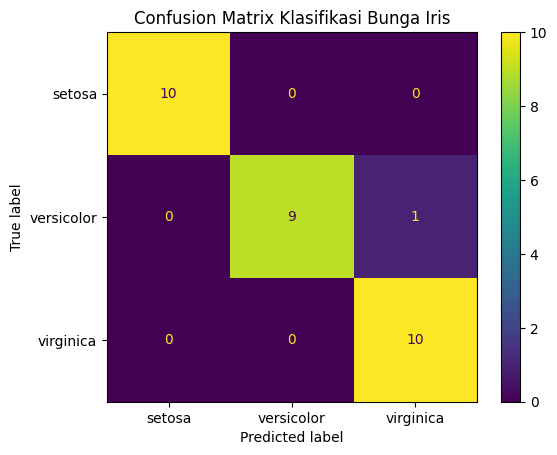

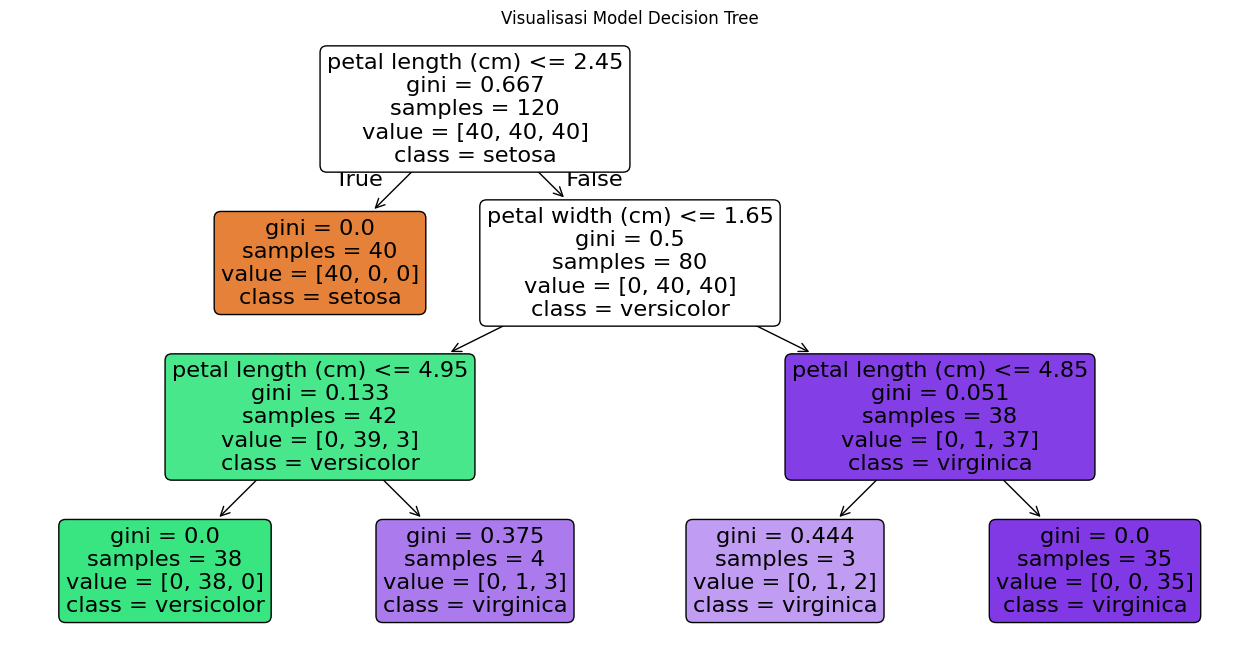


PREDIKSI DATA BARU


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Jenis bunga yang diprediksi: setosa


In [1]:
# ==================================================
# JUDUL:
# Implementasi Machine Learning untuk Klasifikasi
# Data Menggunakan Algoritma Decision Tree
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Memuat dataset
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print("DATASET IRIS")
display(X.head())

# 2. Membagi data menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

# 3. Membuat model Decision Tree
model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# 4. Melatih model
model.fit(X_train, y_train)

print("\nModel berhasil dilatih.")

# 5. Melakukan prediksi
y_pred = model.predict(X_test)

hasil = X_test.copy()
hasil["Kelas Aktual"] = [
    iris.target_names[i] for i in y_test
]
hasil["Hasil Prediksi"] = [
    iris.target_names[i] for i in y_pred
]

print("\nHASIL PREDIKSI")
display(hasil)

# 6. Evaluasi model
akurasi = accuracy_score(y_test, y_pred)

print("\nAKURASI MODEL:", round(akurasi * 100, 2), "%")

print("\nLAPORAN KLASIFIKASI")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

# 7. Menampilkan confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names
)

plt.title("Confusion Matrix Klasifikasi Bunga Iris")
plt.show()

# 8. Visualisasi pohon keputusan
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)

plt.title("Visualisasi Model Decision Tree")
plt.show()

# 9. Prediksi data baru
data_baru = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediksi = model.predict(data_baru)[0]

print("\nPREDIKSI DATA BARU")
display(data_baru)
print("Jenis bunga yang diprediksi:", iris.target_names[prediksi])